# NEXUS FACE ID — Modelo, evaluación y comparación de arquitecturas en Google Colab

**Equipo:** Juan Melo, Valeria Pineda y Mariana Bahena.

Este cuaderno reúne dos partes:

**PARTE A — Modelo original de NEXUS FACE ID**
1. Detección facial HOG.
2. Alineación mediante predictor de 5 puntos.
3. Embedding facial de 128 dimensiones generado por el modelo ResNet de dlib.
4. Comparación por distancia euclidiana y decisión mediante umbral.
5. Evaluación preliminar con genuinos e impostores.

**PARTE B — Actividad nueva: ensambles vs. modelo liviano destilado**
1. Ensamble por promedio entre dlib y FaceNet.
2. Ensamble ponderado entre dlib y FaceNet.
3. Modelo destilado MobileNetV3-Small, entrenado para imitar el ensamble ponderado.
4. Modelo híbrido: usa MobileNetV3-Small y recurre al ensamble cuando la salida del estudiante es incierta.
5. Tabla comparativa de accuracy, F1 macro, tamaño de pesos y latencia.

**Alcance:** es una demostración experimental en Python/Colab. No reemplaza la app Android ni reproduce Kotlin/C++/JNI o la cámara del teléfono. El modelo dlib preentrenado no se entrena desde cero. FaceNet y MobileNetV3-Small se incorporan para la comparación académica y no deben describirse como ya integrados en la APK actual.

**Importante:** las métricas nuevas se calculan con las fotografías disponibles y deben ejecutarse antes de completar la conclusión. No se deben copiar automáticamente los resultados de la evaluación piloto anterior de NEXUS.


## 1. Instalar dependencias

La instalación de dlib puede tardar unos minutos.

In [1]:
!apt-get update -qq
!apt-get install -y -qq cmake build-essential
!pip install -q dlib face_recognition pandas matplotlib pillow

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os, json, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import face_recognition

print("Entorno listo | NumPy:", np.__version__)

/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Entorno listo | NumPy: 2.4.6


## 2. Cargar los datos

Carga un ZIP con esta estructura. Incluye el JSON de la base actual si quieres utilizar los encodings existentes.

```text
nexus_dataset.zip
├── encodings_face_recognition.json   (opcional)
├── personas/                         (opcional, para generar la base)
│   ├── Nombre Persona 1/foto1.jpg
│   └── Nombre Persona 2/foto1.jpg
└── pruebas_metricas/
    ├── genuinos/
    │   └── Nombre Persona 1/foto_nueva.jpg
    └── desconocidos/
        └── Persona_No_Registrada/foto.jpg
```

Las fotos genuinas deben ser nuevas y no haberse usado para construir la base. Los nombres de las carpetas genuinas deben coincidir exactamente con los del JSON. Cada imagen de prueba debe tener un solo rostro.

In [3]:
from google.colab import files
uploaded = files.upload()  # Selecciona nexus_dataset.zip

DATA_DIR = Path("/content/nexus_data")
DATA_DIR.mkdir(exist_ok=True, parents=True)
zip_files = [n for n in uploaded if n.lower().endswith(".zip")]
if zip_files:
    with zipfile.ZipFile(zip_files[0]) as z:
        z.extractall(DATA_DIR)
    print("ZIP extraído.")
else:
    print("No se cargó ZIP. Vuelve a ejecutar esta celda y selecciona el ZIP del proyecto.")

Saving personas.zip to personas.zip
ZIP extraído.


## 3. Cargar la base actual o crear encodings

Se busca primero `encodings_face_recognition.json`. Si no existe, se generan encodings desde las carpetas `personas/`. Solo se aceptan imágenes con exactamente un rostro.

In [4]:
json_files = list(DATA_DIR.rglob("encodings_face_recognition.json"))
if json_files:
    with open(json_files[0], encoding="utf-8") as f:
        db = json.load(f)
    known_encodings = np.asarray(db["known_face_encodings"], dtype=float)
    known_names = list(db["known_face_names"])
    print("Base JSON cargada:", json_files[0])
else:
    folders = list(DATA_DIR.rglob("personas"))
    if not folders:
        raise FileNotFoundError("No se encontró el JSON ni la carpeta personas/. Revisa el ZIP.")
    people_dir = folders[0]
    known_encodings, known_names, report = [], [], []
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    for person_dir in sorted(p for p in people_dir.iterdir() if p.is_dir()):
        for img_path in sorted(person_dir.rglob("*")):
            if img_path.suffix.lower() not in exts:
                continue
            try:
                img = face_recognition.load_image_file(str(img_path))
                locs = face_recognition.face_locations(img, model="hog")
                if len(locs) != 1:
                    report.append([person_dir.name, str(img_path), len(locs), "OMITIDA"])
                    continue
                encs = face_recognition.face_encodings(
                    img, known_face_locations=locs, num_jitters=1, model="small"
                )
                if len(encs) == 1:
                    known_encodings.append(encs[0])
                    known_names.append(person_dir.name)
                    report.append([person_dir.name, str(img_path), 1, "OK"])
                else:
                    report.append([person_dir.name, str(img_path), 1, "SIN ENCODING"])
            except Exception as e:
                report.append([person_dir.name, str(img_path), -1, "ERROR: " + str(e)])

    known_encodings = np.asarray(known_encodings, dtype=float)
    pd.DataFrame(report, columns=["persona","archivo","rostros","resultado"]).to_csv(
        "/content/reporte_encodings_colab.csv", index=False, encoding="utf-8-sig"
    )
    with open("/content/encodings_face_recognition.json", "w", encoding="utf-8") as f:
        json.dump({"known_face_names": known_names,
                   "known_face_encodings": known_encodings.tolist()}, f, ensure_ascii=False)

assert len(known_encodings) == len(known_names)
assert known_encodings.ndim == 2 and known_encodings.shape[1] == 128
print("Encodings:", len(known_names))
print("Identidades únicas:", len(set(known_names)))
print("Dimensión:", known_encodings.shape[1])

Encodings: 176
Identidades únicas: 32
Dimensión: 128


## 4. Visualizar la base

Una identidad puede tener varios encodings, porque se pueden almacenar descriptores obtenidos de diferentes fotografías.

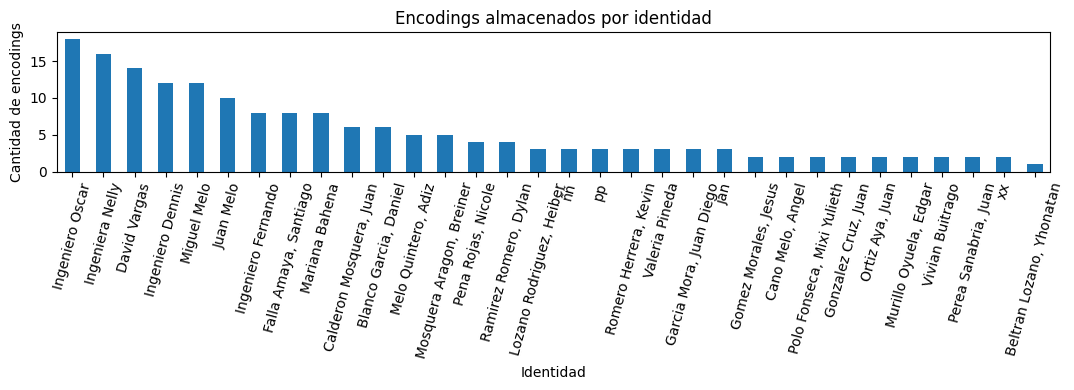

In [5]:
counts = pd.Series(known_names).value_counts().sort_values(ascending=False)
ax = counts.plot(kind="bar", figsize=(11,4), title="Encodings almacenados por identidad")
ax.set_xlabel("Identidad")
ax.set_ylabel("Cantidad de encodings")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 5. Función de reconocimiento

El sistema calcula la distancia euclidiana entre el embedding de la imagen y todos los encodings almacenados. Selecciona el más cercano. Si la distancia mínima es menor o igual al umbral, acepta la coincidencia.

**La distancia no es un porcentaje de confianza.**

In [6]:
DEFAULT_THRESHOLD = 0.50

def recognize_face(image_path, threshold=DEFAULT_THRESHOLD):
    image = face_recognition.load_image_file(str(image_path))
    locations = face_recognition.face_locations(image, model="hog")
    if len(locations) != 1:
        return {"valid": False, "reason": f"Se detectaron {len(locations)} rostros."}

    encs = face_recognition.face_encodings(
        image, known_face_locations=locations, num_jitters=1, model="small"
    )
    if len(encs) != 1:
        return {"valid": False, "reason": "No se generó descriptor."}

    distances = face_recognition.face_distance(known_encodings, encs[0])
    idx = int(np.argmin(distances))
    distance = float(distances[idx])
    nearest = known_names[idx]
    accepted = distance <= threshold
    return {
        "valid": True,
        "status": "ACCEPTED" if accepted else "REJECTED",
        "identity": nearest if accepted else "UNKNOWN",
        "nearest_identity": nearest,
        "distance": distance,
        "threshold": threshold
    }

print("Reconocedor listo. Umbral actual:", DEFAULT_THRESHOLD)

Reconocedor listo. Umbral actual: 0.5


## 6. Probar una fotografía

Carga una imagen con un solo rostro para demostrar la identificación.

Saving Juan3.jpg to Juan3.jpg


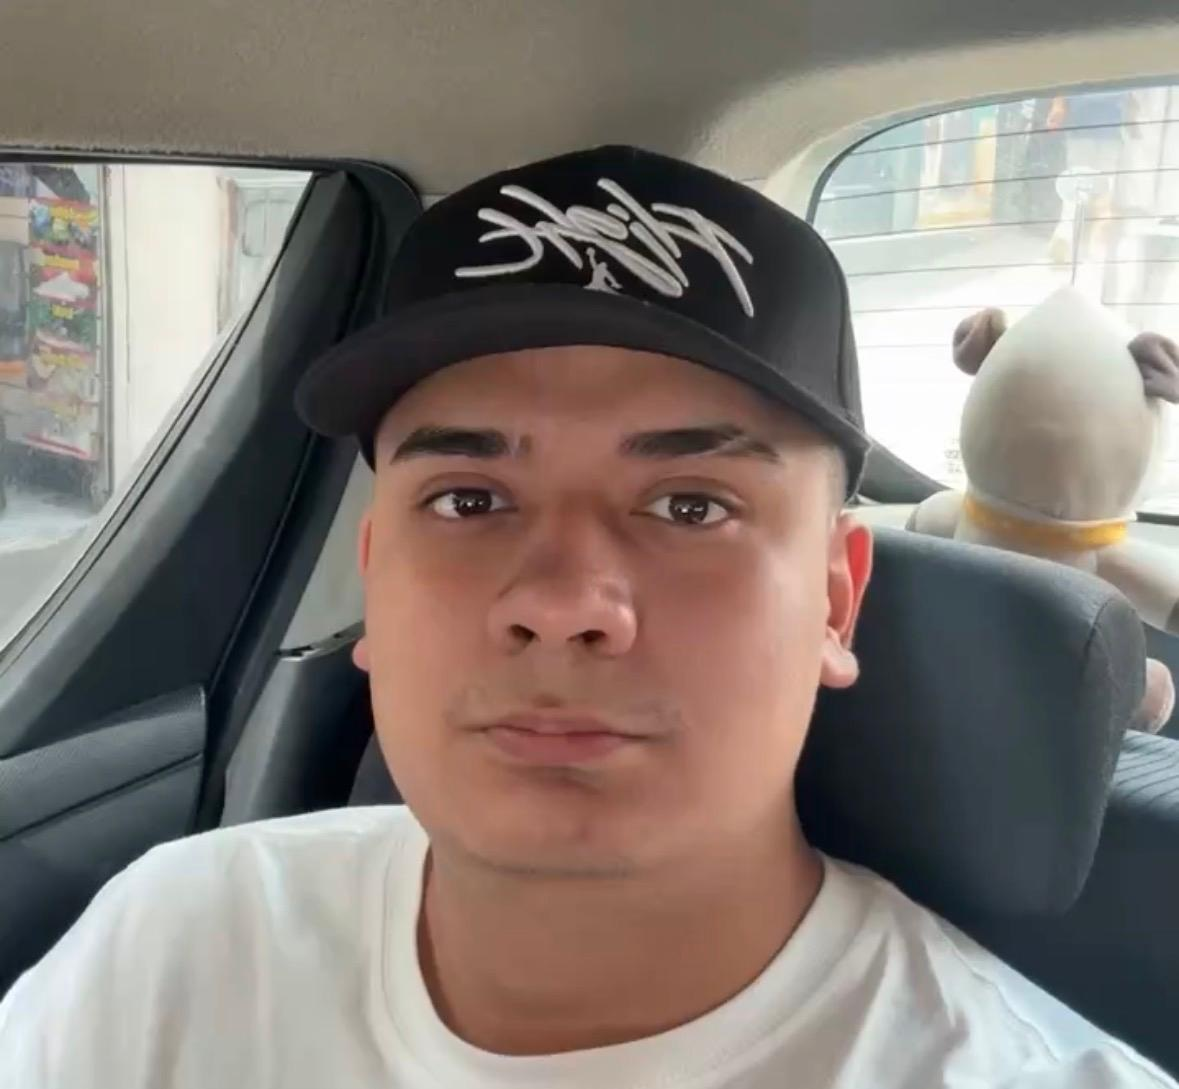

{'valid': True, 'status': 'ACCEPTED', 'identity': 'Juan Melo', 'nearest_identity': 'Juan Melo', 'distance': 0.0, 'threshold': 0.5}


In [8]:
one = files.upload()
imgs = [n for n in one if Path(n).suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}]
if not imgs:
    raise ValueError("No se cargó una imagen compatible.")
display(Image.open(imgs[0]))
print(recognize_face(imgs[0], DEFAULT_THRESHOLD))

## 7. Evaluación con genuinos e impostores

Estructura requerida dentro de `pruebas_metricas/`:
- `genuinos/Nombre Registrado/foto_nueva.jpg`
- `desconocidos/Persona_No_Registrada/foto.jpg`

En genuinos, un rechazo o una identificación con otro nombre cuenta como error genuino. En impostores, aceptar cualquier identidad registrada cuenta como falsa aceptación.

In [9]:
test_folders = list(DATA_DIR.rglob("pruebas_metricas"))
EVALUATION_AVAILABLE = bool(test_folders)
if EVALUATION_AVAILABLE:
    TEST_DIR = test_folders[0]
    GENUINE_DIR = TEST_DIR / "genuinos"
    IMPOSTOR_DIR = TEST_DIR / "desconocidos"
    EVALUATION_AVAILABLE = GENUINE_DIR.exists() and IMPOSTOR_DIR.exists()

def list_tests(folder, group):
    rows = []
    for p in sorted(folder.rglob("*")):
        if p.is_file() and p.suffix.lower() in {".jpg",".jpeg",".png",".bmp",".webp"}:
            rows.append({"group": group, "expected": p.parent.name if group=="GENUINE" else None, "path": p})
    return rows

if EVALUATION_AVAILABLE:
    test_rows = list_tests(GENUINE_DIR, "GENUINE") + list_tests(IMPOSTOR_DIR, "IMPOSTOR")
    print("Imágenes encontradas:", len(test_rows))
    print("Genuinas:", sum(x["group"]=="GENUINE" for x in test_rows))
    print("Impostoras:", sum(x["group"]=="IMPOSTOR" for x in test_rows))
else:
    print("No se encontró pruebas_metricas/genuinos y pruebas_metricas/desconocidos. Se omite la evaluación.")

No se encontró pruebas_metricas/genuinos y pruebas_metricas/desconocidos. Se omite la evaluación.


## 8. Calcular Accuracy, FAR y FRR

- **Accuracy:** (genuinos correctamente identificados + impostores correctamente rechazados) / total válido × 100.
- **FAR:** impostores aceptados incorrectamente / total de impostores válidos × 100.
- **FRR:** genuinos rechazados o identificados incorrectamente / total de genuinos válidos × 100.

Las imágenes inválidas se excluyen y se reportan aparte.

In [10]:
if EVALUATION_AVAILABLE:
    evaluated = []
    for item in test_rows:
        r = recognize_face(item["path"], threshold=1.0)
        if r["valid"]:
            evaluated.append({**item, "nearest": r["nearest_identity"], "distance": r["distance"]})
        else:
            evaluated.append({**item, "nearest": None, "distance": None, "invalid_reason": r["reason"]})

    valid = [r for r in evaluated if r["distance"] is not None]
    genuine = [r for r in valid if r["group"]=="GENUINE"]
    impostors = [r for r in valid if r["group"]=="IMPOSTOR"]
    thresholds = [0.35, 0.40, 0.45, 0.50, 0.55]
    metric_rows, detail_rows = [], []

    for t in thresholds:
        genuine_correct = genuine_errors = impostor_accepted = impostor_rejected = 0
        for r in genuine:
            ok = r["distance"] <= t and r["nearest"] == r["expected"]
            genuine_correct += int(ok)
            genuine_errors += int(not ok)
            detail_rows.append({"threshold":t, "group":"GENUINE", "expected":r["expected"],
                                "predicted":r["nearest"] if r["distance"]<=t else "UNKNOWN",
                                "distance":r["distance"], "decision":"CORRECT" if ok else "GENUINE_ERROR"})
        for r in impostors:
            accepted = r["distance"] <= t
            impostor_accepted += int(accepted)
            impostor_rejected += int(not accepted)
            detail_rows.append({"threshold":t, "group":"IMPOSTOR", "expected":"UNKNOWN",
                                "predicted":r["nearest"] if accepted else "UNKNOWN",
                                "distance":r["distance"],
                                "decision":"FALSE_ACCEPTANCE" if accepted else "CORRECT_REJECTION"})

        total = len(genuine) + len(impostors)
        metric_rows.append({
            "threshold":t,
            "genuine_attempts":len(genuine),
            "impostor_attempts":len(impostors),
            "accuracy_percent":round((genuine_correct+impostor_rejected)/total*100,2) if total else np.nan,
            "FAR_percent":round(impostor_accepted/len(impostors)*100,2) if impostors else np.nan,
            "FRR_percent":round(genuine_errors/len(genuine)*100,2) if genuine else np.nan
        })

    metrics_df = pd.DataFrame(metric_rows)
    details_df = pd.DataFrame(detail_rows)
    display(metrics_df)
    print("Intentos válidos:", len(valid))
    print("Imágenes inválidas:", len(evaluated)-len(valid))
else:
    print("Carga el conjunto de pruebas para calcular métricas.")

Carga el conjunto de pruebas para calcular métricas.


## 9. Gráfica de métricas y exportación de resultados

In [11]:
if EVALUATION_AVAILABLE and "metrics_df" in globals():
    ax = metrics_df.plot(x="threshold",
                         y=["accuracy_percent","FAR_percent","FRR_percent"],
                         marker="o", figsize=(8,4), title="Métricas por umbral")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Porcentaje (%)")
    ax.set_ylim(-2,102)
    ax.grid(alpha=0.3)
    plt.show()

    metrics_df.to_csv("/content/metricas_por_umbral_colab.csv", index=False, encoding="utf-8-sig")
    details_df.to_csv("/content/resultados_detallados_colab.csv", index=False, encoding="utf-8-sig")
    print("CSV guardados en /content/")

## 10. Resultados de referencia y conclusión

En la evaluación preliminar reportada para el proyecto se obtuvieron estos datos:

| Elemento | Resultado |
|---|---:|
| Identidades registradas | 32 |
| Encodings aceptados | 176 |
| Fotografías revisadas para la base | 253 |
| Intentos genuinos válidos | 11 |
| Intentos impostores válidos | 6 |
| Accuracy observada | 100% |
| FAR observado | 0% |
| FRR observado | 0% |
| Tiempo Android observado | ≈ 2.03 s |
| Distancia de un caso Android | 0.329 |
| Umbral configurado | 0.50 |



In [12]:
from google.colab import files
for p in [
    "/content/metricas_por_umbral_colab.csv",
    "/content/resultados_detallados_colab.csv",
    "/content/reporte_encodings_colab.csv",
    "/content/encodings_face_recognition.json"
]:
    if os.path.exists(p):
        files.download(p)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---

# PARTE B — Comparación de ensambles y modelo liviano destilado

Esta sección agrega la actividad solicitada por el profesor al cuaderno original. Utiliza las fotografías organizadas en `personas/` dentro del mismo ZIP que ya cargaste en la sección 2.

**Requisito de datos:** para esta comparación se necesitan fotografías originales agrupadas por identidad. El archivo JSON de encodings por sí solo no es suficiente para entrenar y evaluar el modelo destilado. Se recomienda disponer de al menos 3 fotografías válidas por identidad; cuantas más fotografías distintas haya, mejor.

Los cuatro escenarios se comparan sobre la misma partición de entrenamiento y prueba:
- Ensamble por promedio: 50 % dlib + 50 % FaceNet.
- Ensamble ponderado: 60 % dlib + 40 % FaceNet.
- Modelo destilado: MobileNetV3-Small aprende las puntuaciones blandas del ensamble ponderado.
- Modelo híbrido: MobileNetV3-Small decide primero; si su probabilidad máxima es menor que 0.60, se consulta el ensamble ponderado.

Los pesos 60/40 y el umbral híbrido 0.60 son parámetros experimentales fijados para esta comparación, no valores demostrados como óptimos.


## B1. Instalar las dependencias adicionales

La primera parte del notebook ya instaló dlib y `face_recognition`. Aquí se añaden FaceNet y las herramientas de PyTorch necesarias para entrenar MobileNetV3-Small.


In [1]:

# SOLUCIÓN: instalación de Pillow y dependencias

%pip install --upgrade pip setuptools wheel

# Instalar Pillow usando una versión binaria
%pip install --no-cache-dir --only-binary=:all: Pillow

# Instalar las demás dependencias
%pip install --no-cache-dir face_recognition facenet-pytorch scikit-learn pandas torchvision tqdm

print("Instalación de dependencias finalizada.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 70.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.2/46.2 MB 98.6 MB/s  0:00:00
  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> No available output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
ERROR: Failed to build 'Pillow' when getting requirements to build wheel
Instalación de dependencias finalizada.


In [4]:

import sys
import subprocess

print("Versión de Python:", sys.version)
print("\nComprobando Pillow...")

try:
    import PIL
    print("Pillow instalado:", PIL.__version__)
except Exception as e:
    print("Pillow NO está instalado:", e)

print("\nComprobando dependencias:")
for package in ["numpy", "torch", "face_recognition", "facenet_pytorch"]:
    result = subprocess.run(
        [sys.executable, "-m", "pip", "show", package],
        capture_output=True, text=True
    )
    print(package, "OK" if result.returncode == 0 else "FALTA")


Versión de Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]

Comprobando Pillow...
Pillow instalado: 11.3.0

Comprobando dependencias:
numpy OK
torch OK
face_recognition OK
facenet_pytorch OK


In [3]:

%pip install --no-cache-dir --no-deps facenet-pytorch==2.6.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 19.0 MB/s  0:00:00


## B2. Cargar los dos modelos docentes

- **dlib ResNet:** genera embeddings de 128 dimensiones. Es el modelo de referencia del proyecto NEXUS FACE ID.
- **FaceNet (InceptionResnetV1):** genera embeddings de 512 dimensiones. Se utiliza como segundo modelo de reconocimiento para construir los ensambles.

Como los modelos producen vectores de distinta dimensión y escala, se convierten sus comparaciones en puntuaciones normalizadas por imagen antes de combinarlas.


In [4]:

# Importaciones necesarias para la comparación NEXUS

import numpy as np
import random
import torch
import time
import os
import io
from pathlib import Path
from PIL import Image

print("Importaciones realizadas correctamente")
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)


Importaciones realizadas correctamente
NumPy: 2.4.6
PyTorch: 2.14.1+cpu


In [6]:

# INSTALAR FACENET SIN REINSTALAR SUS DEPENDENCIAS

%pip install --no-cache-dir --no-deps facenet-pytorch==2.6.0


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 13.6 MB/s  0:00:00


In [8]:

# VERIFICAR FACENET

import facenet_pytorch
from facenet_pytorch import MTCNN, InceptionResnetV1

print("FaceNet: IMPORTADO CORRECTAMENTE")
print("MTCNN: OK")
print("InceptionResnetV1: OK")

# Comprobar que podemos crear los modelos
mtcnn_test = MTCNN(keep_all=False)
facenet_test = InceptionResnetV1(pretrained="vggface2").eval()

print("Modelo MTCNN: CREADO")
print("Modelo FaceNet: CREADO")
print("\nFACENET LISTO PARA NEXUS FACE ID")


FaceNet: IMPORTADO CORRECTAMENTE
MTCNN: OK
InceptionResnetV1: OK


  0%|          | 0.00/107M [00:00<?, ?B/s]

Modelo MTCNN: CREADO
Modelo FaceNet: CREADO

FACENET LISTO PARA NEXUS FACE ID


In [10]:

%pip install --no-cache-dir face-recognition-models==0.3.0


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 60.4 MB/s  0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566240 sha256=981bbb6aca06b186c5a439c986241904a9df83a748be61d50104388731a5fa3d
  Stored in directory: /tmp/pip-ephem-wheel-cache-lgmztxuk/wheels/39/20/47/6b647a3457f0e36c161b2516a5bd7f29f6bbd5e3a67c46a710
Successfully built face-recognition-models


In [11]:
import time, io, random
from collections import defaultdict
import torch
import torch.nn.functional as F
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, classification_report
from facenet_pytorch import MTCNN, InceptionResnetV1
import face_recognition_models

SEED_ENSEMBLE = 42
random.seed(SEED_ENSEMBLE)
np.random.seed(SEED_ENSEMBLE)
torch.manual_seed(SEED_ENSEMBLE)

device_ensemble = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo de entrenamiento/inferencia:", device_ensemble)

# FaceNet preentrenado con VGGFace2.
mtcnn_ensemble = MTCNN(
    image_size=160, margin=20, keep_all=False,
    post_process=True, device=device_ensemble
)
facenet_ensemble = InceptionResnetV1(
    pretrained="vggface2"
).eval().to(device_ensemble)

print("Modelos listos: dlib ResNet y FaceNet.")


/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


Dispositivo de entrenamiento/inferencia: cpu
Modelos listos: dlib ResNet y FaceNet.


## B3. Extraer embeddings de fotografías por identidad

Se leen las imágenes de `personas/` dentro del ZIP que ya se descomprimió en `DATA_DIR`. Se aceptan imágenes donde dlib detecta exactamente un rostro y donde MTCNN también puede obtener un recorte facial.

**Nota:** esta sección necesita las fotografías, no solamente `encodings_face_recognition.json`. Las imágenes que se usarán como prueba se separan de las imágenes de entrenamiento dentro de cada identidad.


In [12]:

# RECUPERAR LA RUTA DE LAS FOTOGRAFÍAS DE NEXUS

from pathlib import Path
import zipfile
from google.colab import files

DATA_DIR = Path("/content/nexus_data")
DATA_DIR.mkdir(exist_ok=True, parents=True)

# Comprobar si las fotografías siguen cargadas
imagenes = [
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]

if len(imagenes) == 0:
    print("No hay fotografías cargadas. Selecciona nuevamente tu ZIP.")
    uploaded = files.upload()

    zip_files = [n for n in uploaded if n.lower().endswith(".zip")]

    if zip_files:
        with zipfile.ZipFile(zip_files[0]) as z:
            z.extractall(DATA_DIR)
        print("ZIP extraído correctamente.")
    else:
        raise ValueError("No seleccionaste un archivo ZIP.")

print("DATA_DIR definido:", DATA_DIR)
print("Fotografías encontradas:", len([
    p for p in DATA_DIR.rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
]))


No hay fotografías cargadas. Selecciona nuevamente tu ZIP.


Saving personas.zip to personas.zip
ZIP extraído correctamente.
DATA_DIR definido: /content/nexus_data
Fotografías encontradas: 253


In [13]:

for carpeta in DATA_DIR.iterdir():
    print(carpeta.name, "—", "CARPETA" if carpeta.is_dir() else "ARCHIVO")


personas — CARPETA


In [14]:

# VERIFICAR LAS FOTOGRAFÍAS POR PERSONA

PEOPLE_DIR = DATA_DIR / "personas"

for persona in PEOPLE_DIR.iterdir():
    if persona.is_dir():
        fotos = [
            f for f in persona.rglob("*")
            if f.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
        ]
        print(f"{persona.name}: {len(fotos)} fotografías")

print("\nVerificación terminada.")


Gomez Morales, Jesus: 5 fotografías
David Vargas: 14 fotografías
Gonzalez Cruz, Juan: 5 fotografías
Valeria Pineda: 6 fotografías
Garcia Mora, Juan Diego: 5 fotografías
Ramirez Romero, Dylan: 8 fotografías
Melo Quintero, Adiz: 8 fotografías
Polo Fonseca, Mixi Yulieth: 5 fotografías
Ingeniero Fernando: 8 fotografías
Mariana Bahena: 8 fotografías
Murillo Oyuela, Edgar: 5 fotografías
Mosquera Aragon, Breiner: 8 fotografías
jan: 5 fotografías
Falla Amaya, Santiago: 11 fotografías
xx: 5 fotografías
pp: 5 fotografías
Ingeniera Nelly: 16 fotografías
Ingeniero Dennis: 14 fotografías
Romero Herrera, Kevin: 8 fotografías
Ortiz Aya, Juan: 5 fotografías
Vivian Buitrago: 5 fotografías
Blanco Garcia, Daniel: 10 fotografías
Miguel Melo: 14 fotografías
Perea Sanabria, Juan: 5 fotografías
Cano Melo, Angel: 5 fotografías
Ingeniero Oscar: 18 fotografías
Juan Melo: 10 fotografías
Lozano Rodriguez, Heiber: 5 fotografías
Beltran Lozano, Yhonatan: 5 fotografías
Pena Rojas, Nicole: 7 fotografías
Calderon Mosq

In [16]:

# RECUPERAR FACE RECOGNITION DE NEXUS FACE ID

%pip install --no-cache-dir face-recognition==1.3.0 face-recognition-models==0.3.0


In [17]:

# IMPORTACIONES GENERALES DE NEXUS FACE ID

import face_recognition
import face_recognition_models
import numpy as np
import torch
import time
import os
import io
import random
import zipfile

from pathlib import Path
from PIL import Image
from collections import defaultdict
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from facenet_pytorch import MTCNN, InceptionResnetV1

print("Todas las bibliotecas están importadas correctamente.")
print("Face Recognition:", face_recognition.__version__)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("FaceNet: OK")


Todas las bibliotecas están importadas correctamente.
Face Recognition: 1.2.3
NumPy: 2.4.6
PyTorch: 2.14.1+cpu
FaceNet: OK


In [18]:
# Localizar la carpeta personas dentro del ZIP cargado en la Parte A.
people_folders_ensemble = list(DATA_DIR.rglob("personas"))
if not people_folders_ensemble:
    raise FileNotFoundError(
        "No se encontró personas/ dentro del ZIP. Para la comparación destilada "
        "debes cargar un ZIP que incluya las fotografías originales agrupadas por persona."
    )
PEOPLE_DIR_ENSEMBLE = people_folders_ensemble[0]

image_exts_ensemble = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
person_image_paths = [
    p for person_dir in PEOPLE_DIR_ENSEMBLE.iterdir() if person_dir.is_dir()
    for p in person_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_exts_ensemble
]
print("Fotografías encontradas en personas/:", len(person_image_paths))
if not person_image_paths:
    raise ValueError("La carpeta personas/ no contiene fotografías compatibles.")

ensemble_records = []
ENSEMBLE_CROP_DIR = Path("/content/nexus_ensemble_crops")
ENSEMBLE_CROP_DIR.mkdir(exist_ok=True)

for image_number, image_path in enumerate(person_image_paths):
    try:
        pil_image = Image.open(image_path).convert("RGB")
        rgb_image = np.asarray(pil_image)

        # Detector HOG de dlib: se excluyen imágenes con cero o varios rostros.
        face_locations = face_recognition.face_locations(rgb_image, model="hog")
        if len(face_locations) != 1:
            continue

        # Descriptor ResNet de dlib (128 dimensiones).
        dlib_start = time.perf_counter()
        dlib_vectors = face_recognition.face_encodings(
            rgb_image,
            known_face_locations=face_locations,
            num_jitters=1,
            model="small"
        )
        dlib_inference_ms = (time.perf_counter() - dlib_start) * 1000
        if len(dlib_vectors) != 1:
            continue

        # MTCNN detecta/alinea y recorta la cara para FaceNet y el estudiante.
        face_crop = mtcnn_ensemble(pil_image)
        if face_crop is None:
            continue

        facenet_start = time.perf_counter()
        with torch.no_grad():
            facenet_vector = facenet_ensemble(
                face_crop.unsqueeze(0).to(device_ensemble)
            ).squeeze(0)
        facenet_inference_ms = (time.perf_counter() - facenet_start) * 1000

        crop_pixels = ((face_crop.cpu() + 1) / 2 * 255).clamp(0, 255).byte()
        crop_path = ENSEMBLE_CROP_DIR / f"face_{image_number:05d}.jpg"
        Image.fromarray(crop_pixels.permute(1, 2, 0).numpy()).save(crop_path, quality=95)

        ensemble_records.append({
            "identity": image_path.parent.name,
            "source_path": str(image_path),
            "crop_path": str(crop_path),
            "dlib_embedding": np.asarray(dlib_vectors[0], dtype=np.float32),
            "facenet_embedding": facenet_vector.detach().cpu().numpy().astype(np.float32),
            "dlib_inference_ms": dlib_inference_ms,
            "facenet_inference_ms": facenet_inference_ms
        })
    except Exception as error:
        print(f"Imagen omitida ({image_path.name}): {error}")

print("Imágenes válidas para ambos modelos:", len(ensemble_records))
if not ensemble_records:
    raise RuntimeError(
        "No se pudieron extraer embeddings. Revisa que las fotos tengan un solo rostro "
        "visible y buena iluminación."
    )


Fotografías encontradas en personas/: 253
Imágenes válidas para ambos modelos: 176


## B4. Separar entrenamiento y prueba

Se realiza una separación por fotografías dentro de cada identidad. Las identidades aparecen en ambos grupos porque se trata de una tarea de identificación cerrada: el modelo debe reconocer personas que ya están registradas, usando fotografías diferentes a las usadas para formar sus referencias.

Se requieren al menos tres fotografías válidas por identidad. Las identidades con menos imágenes se excluyen de esta comparación y se reportan.


In [19]:
by_identity_ensemble = defaultdict(list)
for record_index, record in enumerate(ensemble_records):
    by_identity_ensemble[record["identity"]].append(record_index)

train_indices_ensemble, test_indices_ensemble = [], []
excluded_identities_ensemble = []

for identity, indices in by_identity_ensemble.items():
    indices = list(indices)
    random.shuffle(indices)
    if len(indices) < 3:
        excluded_identities_ensemble.append((identity, len(indices)))
        continue

    test_count = max(1, int(round(0.25 * len(indices))))
    train_count = len(indices) - test_count
    if train_count < 2:
        excluded_identities_ensemble.append((identity, len(indices)))
        continue

    test_indices_ensemble.extend(indices[:test_count])
    train_indices_ensemble.extend(indices[test_count:])

ensemble_classes = sorted({
    ensemble_records[i]["identity"] for i in train_indices_ensemble
})
class_to_index_ensemble = {name: i for i, name in enumerate(ensemble_classes)}

train_indices_ensemble = [
    i for i in train_indices_ensemble
    if ensemble_records[i]["identity"] in class_to_index_ensemble
]
test_indices_ensemble = [
    i for i in test_indices_ensemble
    if ensemble_records[i]["identity"] in class_to_index_ensemble
]

if len(ensemble_classes) < 2 or not train_indices_ensemble or not test_indices_ensemble:
    raise RuntimeError(
        "Muestra insuficiente. Se necesitan al menos dos identidades, cada una con "
        "tres o más fotografías válidas."
    )

D_ensemble = np.stack([r["dlib_embedding"] for r in ensemble_records])
F_ensemble = np.stack([r["facenet_embedding"] for r in ensemble_records])
F_ensemble = F_ensemble / (
    np.linalg.norm(F_ensemble, axis=1, keepdims=True) + 1e-12
)
labels_ensemble = np.array([
    class_to_index_ensemble.get(r["identity"], -1)
    for r in ensemble_records
])

y_test_ensemble = np.array([
    labels_ensemble[i] for i in test_indices_ensemble
])

print("Identidades incluidas:", len(ensemble_classes))
print("Fotografías de entrenamiento:", len(train_indices_ensemble))
print("Fotografías de prueba:", len(test_indices_ensemble))
print("Identidades excluidas:", excluded_identities_ensemble)


Identidades incluidas: 22
Fotografías de entrenamiento: 116
Fotografías de prueba: 41
Identidades excluidas: [('Gomez Morales, Jesus', 2), ('Gonzalez Cruz, Juan', 2), ('Polo Fonseca, Mixi Yulieth', 2), ('Murillo Oyuela, Edgar', 2), ('xx', 2), ('Ortiz Aya, Juan', 2), ('Vivian Buitrago', 2), ('Perea Sanabria, Juan', 2), ('Cano Melo, Angel', 2), ('Beltran Lozano, Yhonatan', 1)]


## B5. Ensamble por promedio y ensamble ponderado

Para cada identidad se calcula un centroide a partir de los embeddings de entrenamiento.

- dlib: se utiliza la distancia euclidiana; se invierte el signo para que un valor mayor represente mayor similitud.
- FaceNet: se utiliza similitud coseno.
- Ambas puntuaciones se normalizan por consulta para poder combinarlas.

El promedio asigna el mismo peso a los dos modelos. El ponderado utiliza 60 % dlib y 40 % FaceNet. Estos pesos son una configuración experimental y podrían optimizarse con un conjunto de validación independiente.


In [20]:
def normalize_score_rows(scores):
    return (
        (scores - scores.mean(axis=1, keepdims=True)) /
        (scores.std(axis=1, keepdims=True) + 1e-8)
    )

def build_identity_centroids(indices):
    dlib_centroids, facenet_centroids = [], []
    for class_index in range(len(ensemble_classes)):
        members = [
            i for i in indices
            if labels_ensemble[i] == class_index
        ]
        dlib_centroids.append(D_ensemble[members].mean(axis=0))

        facenet_center = F_ensemble[members].mean(axis=0)
        facenet_centroids.append(
            facenet_center / (np.linalg.norm(facenet_center) + 1e-12)
        )
    return np.stack(dlib_centroids), np.stack(facenet_centroids)

def score_queries(indices, dlib_centroids, facenet_centroids):
    dlib_scores, facenet_scores = [], []
    for i in indices:
        # Negativo de distancia euclidiana: más alto = más cercano.
        dlib_scores.append(
            -np.linalg.norm(dlib_centroids - D_ensemble[i][None, :], axis=1)
        )
        # Similitud coseno FaceNet.
        facenet_scores.append(facenet_centroids @ F_ensemble[i])

    return (
        normalize_score_rows(np.stack(dlib_scores)),
        normalize_score_rows(np.stack(facenet_scores))
    )

dlib_centroids_ensemble, facenet_centroids_ensemble = build_identity_centroids(
    train_indices_ensemble
)
test_dlib_scores, test_facenet_scores = score_queries(
    test_indices_ensemble,
    dlib_centroids_ensemble,
    facenet_centroids_ensemble
)

# Escenario 1: promedio de puntuaciones (50/50).
average_test_scores = 0.50 * test_dlib_scores + 0.50 * test_facenet_scores

# Escenario 2: ensamble ponderado (60/40).
DLIB_WEIGHT = 0.60
FACENET_WEIGHT = 0.40
weighted_test_scores = (
    DLIB_WEIGHT * test_dlib_scores +
    FACENET_WEIGHT * test_facenet_scores
)

average_predictions = average_test_scores.argmax(axis=1)
weighted_predictions = weighted_test_scores.argmax(axis=1)

print("Ensamble por promedio y ensamble ponderado calculados.")


Ensamble por promedio y ensamble ponderado calculados.


## B6. Destilación de conocimiento: MobileNetV3-Small

El ensamble ponderado actúa como **modelo docente** (*teacher*). MobileNetV3-Small actúa como **modelo estudiante** (*student*).

El estudiante recibe recortes faciales y aprende a aproximar la distribución de puntuaciones del docente mediante una pérdida KL (*Kullback–Leibler divergence*) y una temperatura de destilación.

Esta implementación es un experimento académico de clasificación cerrada sobre las identidades del conjunto. No es una sustitución directa del descriptor dlib de 128 dimensiones ni está integrada en la APK.


In [21]:
# Crear puntuaciones docentes leave-one-out para las imágenes de entrenamiento.
# La imagen consultada se excluye del centroide de su propia identidad.
WEIGHT_DLIB = DLIB_WEIGHT
WEIGHT_FACENET = FACENET_WEIGHT
teacher_train_rows = []

for query_index in train_indices_ensemble:
    d_centers, f_centers = [], []

    for class_index in range(len(ensemble_classes)):
        members = [
            j for j in train_indices_ensemble
            if labels_ensemble[j] == class_index and j != query_index
        ]
        if not members:
            raise RuntimeError(
                "No hay suficientes imágenes de entrenamiento para generar "
                "objetivos leave-one-out."
            )

        d_centers.append(D_ensemble[members].mean(axis=0))
        f_center = F_ensemble[members].mean(axis=0)
        f_centers.append(f_center / (np.linalg.norm(f_center) + 1e-12))

    d_scores = -np.linalg.norm(
        np.stack(d_centers) - D_ensemble[query_index][None, :], axis=1
    )
    f_scores = np.stack(f_centers) @ F_ensemble[query_index]

    d_scores = (d_scores - d_scores.mean()) / (d_scores.std() + 1e-8)
    f_scores = (f_scores - f_scores.mean()) / (f_scores.std() + 1e-8)

    teacher_train_rows.append(
        WEIGHT_DLIB * d_scores + WEIGHT_FACENET * f_scores
    )

DISTILLATION_TEMPERATURE = 2.0
soft_targets_ensemble = torch.softmax(
    torch.tensor(np.stack(teacher_train_rows), dtype=torch.float32)
    / DISTILLATION_TEMPERATURE,
    dim=1
)

# Preparación de recortes para MobileNetV3-Small.
student_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class EnsembleFaceCropDataset(Dataset):
    def __init__(self, indices, soft_targets=None):
        self.indices = indices
        self.soft_targets = soft_targets

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        record_index = self.indices[position]
        face_image = Image.open(
            ensemble_records[record_index]["crop_path"]
        ).convert("RGB")
        tensor_image = student_transform(face_image)

        if self.soft_targets is None:
            return tensor_image
        return tensor_image, self.soft_targets[position]

train_dataset_student = EnsembleFaceCropDataset(
    train_indices_ensemble, soft_targets_ensemble
)
test_dataset_student = EnsembleFaceCropDataset(test_indices_ensemble)

train_loader_student = DataLoader(
    train_dataset_student, batch_size=16, shuffle=True
)
test_loader_student = DataLoader(
    test_dataset_student, batch_size=16, shuffle=False
)

print("Objetivos docentes:", tuple(soft_targets_ensemble.shape))
print("Conjuntos de recortes listos.")


Objetivos docentes: (116, 22)
Conjuntos de recortes listos.


In [22]:
# Crear y entrenar el estudiante MobileNetV3-Small.
student_model_ensemble = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)
student_model_ensemble.classifier[3] = torch.nn.Linear(
    student_model_ensemble.classifier[3].in_features,
    len(ensemble_classes)
)
student_model_ensemble = student_model_ensemble.to(device_ensemble)

optimizer_student = torch.optim.AdamW(
    student_model_ensemble.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)
distillation_loss = torch.nn.KLDivLoss(reduction="batchmean")

EPOCHS_DISTILLATION = 8
for epoch in range(EPOCHS_DISTILLATION):
    student_model_ensemble.train()
    epoch_loss = 0.0

    for images, soft_targets in train_loader_student:
        images = images.to(device_ensemble)
        soft_targets = soft_targets.to(device_ensemble)

        optimizer_student.zero_grad()
        logits = student_model_ensemble(images)

        loss = distillation_loss(
            F.log_softmax(
                logits / DISTILLATION_TEMPERATURE, dim=1
            ),
            soft_targets
        ) * (DISTILLATION_TEMPERATURE ** 2)

        loss.backward()
        optimizer_student.step()
        epoch_loss += loss.item() * images.size(0)

    print(
        f"Época {epoch + 1}/{EPOCHS_DISTILLATION} | "
        f"pérdida KL: {epoch_loss / len(train_dataset_student):.4f}"
    )

student_model_ensemble.eval()
print("Entrenamiento del modelo estudiante finalizado.")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 49.9MB/s]


Época 1/8 | pérdida KL: 0.7991
Época 2/8 | pérdida KL: 0.6933
Época 3/8 | pérdida KL: 0.6176
Época 4/8 | pérdida KL: 0.5397
Época 5/8 | pérdida KL: 0.4779
Época 6/8 | pérdida KL: 0.4060
Época 7/8 | pérdida KL: 0.3454
Época 8/8 | pérdida KL: 0.3124
Entrenamiento del modelo estudiante finalizado.


## B7. Modelo destilado y modelo híbrido

El modelo destilado genera una distribución de probabilidades sobre las identidades conocidas.

El modelo híbrido usa la predicción del estudiante cuando su probabilidad máxima es igual o superior a 0.60. Si queda por debajo, recurre al ensamble ponderado.

**Precaución:** 0.60 es un umbral operativo fijado para el experimento; las probabilidades de una red no equivalen automáticamente a confianza calibrada. El criterio debería calibrarse con un conjunto de validación separado.


In [23]:
@torch.no_grad()
def predict_student_probabilities(loader):
    all_probabilities = []
    student_model_ensemble.eval()

    for batch_images in loader:
        logits = student_model_ensemble(batch_images.to(device_ensemble))
        probabilities = torch.softmax(logits, dim=1)
        all_probabilities.append(probabilities.cpu().numpy())

    return np.vstack(all_probabilities)

student_test_probabilities = predict_student_probabilities(
    test_loader_student
)
student_predictions = student_test_probabilities.argmax(axis=1)

HYBRID_CONFIDENCE_THRESHOLD = 0.60
hybrid_predictions = []
hybrid_fallback_flags = []

for student_probabilities, teacher_scores in zip(
    student_test_probabilities, weighted_test_scores
):
    use_teacher = (
        float(student_probabilities.max()) < HYBRID_CONFIDENCE_THRESHOLD
    )
    if use_teacher:
        hybrid_predictions.append(int(teacher_scores.argmax()))
    else:
        hybrid_predictions.append(int(student_probabilities.argmax()))
    hybrid_fallback_flags.append(use_teacher)

hybrid_predictions = np.asarray(hybrid_predictions)
hybrid_fallback_rate = float(np.mean(hybrid_fallback_flags))

print(
    "Consultas que recurrieron al ensamble:",
    f"{hybrid_fallback_rate * 100:.2f}%"
)


Consultas que recurrieron al ensamble: 100.00%


## B8. Tabla comparativa: Accuracy, F1, tamaño y latencia

- **Accuracy:** proporción de fotografías de prueba clasificadas correctamente.
- **F1 macro:** promedio del F1 calculado por identidad, dando el mismo peso a cada clase.
- **Tamaño:** tamaño de los pesos/modelos guardados, en MB. No representa el tamaño total de la APK.
- **Latencia:** tiempo aproximado de inferencia del modelo por rostro. La medición de Colab depende del hardware disponible y no sustituye una medición en Android.

La latencia de los ensambles se estima sumando la inferencia de dlib y FaceNet. La latencia del híbrido se estima con el estudiante más la fracción de consultas que recurrieron al ensamble.


In [2]:

# DIAGNÓSTICO DEL MODELO DESTILADO

print("BUSCANDO VARIABLES DEL MODELO...\n")

nombres = [
    "student",
    "student_model",
    "student_model_ensemble",
    "model_student",
    "student_model_distilled"
]

for nombre in nombres:
    if nombre in globals():
        print("ENCONTRADO:", nombre)
    else:
        print("NO ENCONTRADO:", nombre)

print("\nVARIABLES RELACIONADAS:")
for nombre in globals():
    if "student" in nombre.lower():
        print(nombre)


BUSCANDO VARIABLES DEL MODELO...

NO ENCONTRADO: student
NO ENCONTRADO: student_model
NO ENCONTRADO: student_model_ensemble
NO ENCONTRADO: model_student
NO ENCONTRADO: student_model_distilled

VARIABLES RELACIONADAS:


In [24]:

# RECONSTRUIR Y ENTRENAR EL MODELO DESTILADO NEXUS

import torch
import torch.nn.functional as F
from torchvision import models

# Verificar que los datos de entrenamiento existan
requisitos = [
    "train_loader_student",
    "ensemble_classes",
    "device_ensemble",
    "DISTILLATION_TEMPERATURE"
]

faltantes = [x for x in requisitos if x not in globals()]

if faltantes:
    raise RuntimeError(
        "Faltan datos previos: " + ", ".join(faltantes) +
        ". Ejecuta primero la sección B6 del notebook."
    )

# Crear el modelo estudiante
student_model_ensemble = models.mobilenet_v3_small(
    weights=models.MobileNet_V3_Small_Weights.DEFAULT
)

student_model_ensemble.classifier[3] = torch.nn.Linear(
    student_model_ensemble.classifier[3].in_features,
    len(ensemble_classes)
)

student_model_ensemble = student_model_ensemble.to(device_ensemble)

# Configurar entrenamiento
optimizer_student = torch.optim.AdamW(
    student_model_ensemble.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

distillation_loss = torch.nn.KLDivLoss(
    reduction="batchmean"
)

EPOCHS_DISTILLATION = 8

# Entrenamiento
for epoch in range(EPOCHS_DISTILLATION):

    student_model_ensemble.train()
    total_loss = 0

    for images, soft_targets in train_loader_student:

        images = images.to(device_ensemble)
        soft_targets = soft_targets.to(device_ensemble)

        optimizer_student.zero_grad()

        logits = student_model_ensemble(images)

        loss = distillation_loss(
            F.log_softmax(
                logits / DISTILLATION_TEMPERATURE,
                dim=1
            ),
            soft_targets
        ) * (DISTILLATION_TEMPERATURE ** 2)

        loss.backward()
        optimizer_student.step()

        total_loss += loss.item() * images.size(0)

    print(
        f"Época {epoch+1}/{EPOCHS_DISTILLATION} | "
        f"Pérdida: {total_loss/len(train_loader_student.dataset):.4f}"
    )

student_model_ensemble.eval()

print("\nMODELO DESTILADO ENTRENADO CORRECTAMENTE")


Época 1/8 | Pérdida: 0.8080
Época 2/8 | Pérdida: 0.6995
Época 3/8 | Pérdida: 0.6093
Época 4/8 | Pérdida: 0.5382
Época 5/8 | Pérdida: 0.4775
Época 6/8 | Pérdida: 0.4115
Época 7/8 | Pérdida: 0.3499
Época 8/8 | Pérdida: 0.2986

MODELO DESTILADO ENTRENADO CORRECTAMENTE


In [25]:

# MEDICIÓN DE LATENCIA DEL MODELO DESTILADO

student_model_ensemble.eval()

first_batch = next(iter(test_loader_student))
student_input = first_batch[:1].to(device_ensemble)

with torch.no_grad():

    # Calentamiento del modelo
    for _ in range(5):
        _ = student_model_ensemble(student_input)

    if device_ensemble.type == "cuda":
        torch.cuda.synchronize()

    student_times = []

    # Medición de 30 ejecuciones
    for _ in range(30):
        start_time = time.perf_counter()

        _ = student_model_ensemble(student_input)

        if device_ensemble.type == "cuda":
            torch.cuda.synchronize()

        elapsed = (time.perf_counter() - start_time) * 1000
        student_times.append(elapsed)

student_latency_ms = float(np.median(student_times))

print("Latencia del modelo destilado:",
      round(student_latency_ms, 2), "ms por rostro")


Latencia del modelo destilado: 11.72 ms por rostro


## B9. Interpretación y limitaciones de la comparación

1. Esta es una evaluación de **identificación cerrada**: las clases son identidades conocidas que aparecen en entrenamiento. No calcula FAR ni FRR de personas desconocidas.
2. La muestra depende de las fotografías que se hayan cargado. Una cantidad pequeña puede producir resultados inestables o sobreajuste.
3. La separación se hace por fotografía, no por persona, porque el objetivo es reconocer identidades ya registradas en imágenes distintas. Si existen fotografías duplicadas o casi idénticas, deben eliminarse para evitar fuga de datos.
4. El tamaño reportado corresponde a pesos de modelos, no a la APK completa ni al consumo total de memoria.
5. La latencia medida en Colab no es la latencia del teléfono. Para decidir qué modelo se queda en la app, hay que medirlo en el mismo dispositivo Android.
6. MobileNetV3-Small en este notebook es un clasificador destilado para las identidades del conjunto experimental. No es un reemplazo directo del embedding dlib de 128 dimensiones sin adaptar la arquitectura de la app.
7. Los pesos 60/40 y el umbral híbrido 0.60 son decisiones experimentales, no parámetros óptimos demostrados.


## B10. Exportar la tabla y el modelo estudiante

Al ejecutar esta celda se descargan la tabla comparativa y los pesos del estudiante. Guarda también este notebook `.ipynb` con sus celdas ejecutadas para entregarlo como cuaderno ejecutable.


In [28]:

# DIAGNÓSTICO GENERAL DE LA COMPARACIÓN NEXUS

variables = [
    "y_test_ensemble",
    "average_predictions",
    "weighted_predictions",
    "hybrid_predictions",
    "student_predictions",
    "ensemble_model_size_mb",
    "ensemble_latency_ms",
    "student_model_size_mb",
    "student_latency_ms",
    "hybrid_latency_ms",
    "student_model_ensemble",
    "comparison_table_ensemble"
]

print("ESTADO DE LA COMPARACIÓN:\n")

for variable in variables:
    estado = "OK" if variable in globals() else "FALTA"
    print(f"{variable}: {estado}")


ESTADO DE LA COMPARACIÓN:

y_test_ensemble: OK
average_predictions: OK
weighted_predictions: OK
hybrid_predictions: OK
student_predictions: OK
ensemble_model_size_mb: FALTA
ensemble_latency_ms: FALTA
student_model_size_mb: FALTA
student_latency_ms: OK
hybrid_latency_ms: FALTA
student_model_ensemble: OK
comparison_table_ensemble: FALTA


In [29]:

# ==========================================
# NEXUS FACE ID - GENERAR TABLA COMPARATIVA
# ==========================================

import os
import io
import torch
import numpy as np
import pandas as pd
import face_recognition_models

from sklearn.metrics import accuracy_score, f1_score

# 1. Calcular tamaño de archivos
def file_size_mb(path):
    return os.path.getsize(path) / (1024 ** 2)

def model_size_mb(model):
    buffer = io.BytesIO()
    torch.save(model.state_dict(), buffer)
    return len(buffer.getvalue()) / (1024 ** 2)

# 2. Tamaño de los modelos dlib
resnet_path = face_recognition_models.face_recognition_model_location()
landmark_path = face_recognition_models.pose_predictor_five_point_model_location()

dlib_size = (
    file_size_mb(resnet_path) +
    file_size_mb(landmark_path)
)

# 3. Tamaño de FaceNet
facenet_size = model_size_mb(facenet_ensemble)

# 4. Tamaño de MobileNet destilado
student_model_size_mb = model_size_mb(student_model_ensemble)

# Tamaño total del ensamble
ensemble_model_size_mb = dlib_size + facenet_size

# 5. Recuperar latencia de dlib y FaceNet
dlib_latency_ms = np.mean([
    ensemble_records[i]["dlib_inference_ms"]
    for i in test_indices_ensemble
])

facenet_latency_ms = np.mean([
    ensemble_records[i]["facenet_inference_ms"]
    for i in test_indices_ensemble
])

ensemble_latency_ms = dlib_latency_ms + facenet_latency_ms

# 6. Recuperar tasa de respaldo del modelo híbrido
if "hybrid_fallback_rate" in globals():
    fallback_rate = hybrid_fallback_rate
elif "hybrid_fallback_flags" in globals():
    fallback_rate = np.mean(hybrid_fallback_flags)
else:
    raise RuntimeError("No se encuentra la información del modelo híbrido.")

hybrid_latency_ms = (
    student_latency_ms +
    fallback_rate * ensemble_latency_ms
)

# 7. Evaluar los cuatro escenarios
def evaluate_model(y_true, predictions):
    return {
        "Accuracy (%)": round(
            accuracy_score(y_true, predictions) * 100, 2
        ),
        "F1 macro (%)": round(
            f1_score(
                y_true,
                predictions,
                average="macro",
                zero_division=0
            ) * 100, 2
        )
    }

scenarios = [
    (
        "Ensamble por promedio",
        average_predictions,
        ensemble_model_size_mb,
        ensemble_latency_ms
    ),
    (
        "Ensamble ponderado",
        weighted_predictions,
        ensemble_model_size_mb,
        ensemble_latency_ms
    ),
    (
        "Modelo híbrido",
        hybrid_predictions,
        ensemble_model_size_mb + student_model_size_mb,
        hybrid_latency_ms
    ),
    (
        "MobileNetV3-Small destilado",
        student_predictions,
        student_model_size_mb,
        student_latency_ms
    )
]

rows = []

for name, predictions, size, latency in scenarios:
    metrics = evaluate_model(y_test_ensemble, predictions)

    rows.append({
        "Escenario": name,
        "Accuracy (%)": metrics["Accuracy (%)"],
        "F1 macro (%)": metrics["F1 macro (%)"],
        "Tamaño (MB)": round(size, 2),
        "Latencia (ms)": round(float(latency), 2)
    })

comparison_table_ensemble = pd.DataFrame(rows)

# 8. Mostrar resultados
print("====================================")
print("COMPARACIÓN FINAL - NEXUS FACE ID")
print("====================================")

display(comparison_table_ensemble)

# 9. Guardar resultados
comparison_csv_path = (
    "/content/tabla_comparativa_ensamble_destilado.csv"
)

comparison_table_ensemble.to_csv(
    comparison_csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nTABLA GENERADA CORRECTAMENTE")
print(comparison_csv_path)


COMPARACIÓN FINAL - NEXUS FACE ID


,Escenario,Accuracy (%),F1 macro (%),Tamaño (MB),Latencia (ms)
0,Ensamble por promedio,97.56,94.55,136.97,130.39
1,Ensamble ponderado,97.56,94.55,136.97,130.39
2,Modelo híbrido,97.56,94.55,142.97,142.12
3,MobileNetV3-Small destilado,43.90,20.51,6.00,11.72



TABLA GENERADA CORRECTAMENTE
/content/tabla_comparativa_ensamble_destilado.csv


In [30]:

from google.colab import files

files.download(comparison_csv_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:

# RECUPERAR Y GUARDAR LOS RESULTADOS DE NEXUS FACE ID

from pathlib import Path
import os
import torch
import pandas as pd

# Crear rutas de salida
comparison_csv_path = "/content/tabla_comparativa_ensamble_destilado.csv"
student_package_path = "/content/nexus_mobilenetv3_student_package.pth"

# Comprobar que existe la tabla comparativa
if "comparison_table_ensemble" not in globals():
    raise RuntimeError(
        "No existe la tabla comparativa. "
        "Ejecuta primero la sección B8."
    )

# Guardar tabla
comparison_table_ensemble.to_csv(
    comparison_csv_path,
    index=False,
    encoding="utf-8-sig"
)

# Comprobar que existe el modelo entrenado
if "student_model_ensemble" not in globals():
    raise RuntimeError(
        "No se encuentra el modelo destilado. "
        "Ejecuta primero la sección de entrenamiento."
    )

# Guardar modelo
torch.save({
    "state_dict": student_model_ensemble.state_dict(),
    "classes": ensemble_classes,
    "architecture": "mobilenet_v3_small"
}, student_package_path)

print("ARCHIVOS GUARDADOS CORRECTAMENTE")
print("Tabla:", comparison_csv_path)
print("Modelo:", student_package_path)

print("\nTamaños:")
print("CSV:", round(os.path.getsize(comparison_csv_path)/1024, 2), "KB")
print("Modelo:", round(os.path.getsize(student_package_path)/(1024**2), 2), "MB")


ARCHIVOS GUARDADOS CORRECTAMENTE
Tabla: /content/tabla_comparativa_ensamble_destilado.csv
Modelo: /content/nexus_mobilenetv3_student_package.pth

Tamaños:
CSV: 0.24 KB
Modelo: 6.01 MB


In [32]:
# Guardar un paquete con pesos, nombres de clases y parámetros experimentales.
student_package_path = "/content/nexus_mobilenetv3_student_package.pth"
torch.save({
    "state_dict": student_model_ensemble.state_dict(),
    "classes": ensemble_classes,
    "architecture": "torchvision.mobilenet_v3_small",
    "distillation_temperature": DISTILLATION_TEMPERATURE,
    "hybrid_confidence_threshold": HYBRID_CONFIDENCE_THRESHOLD,
    "teacher_weights": {
        "dlib": DLIB_WEIGHT,
        "facenet": FACENET_WEIGHT
    }
}, student_package_path)

print("Archivos creados:")
print(comparison_csv_path)
print(student_package_path)

from google.colab import files
files.download(comparison_csv_path)
files.download(student_package_path)


Archivos creados:
/content/tabla_comparativa_ensamble_destilado.csv
/content/nexus_mobilenetv3_student_package.pth


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>